In [1]:
import torch
# torch.autograd.set_detect_anomaly(True)
from torch.utils.data import WeightedRandomSampler
from torch.utils.data import DataLoader as CNNDataLoader
from torch_geometric.loader import DataLoader as GNNDataLoader
from torch.optim.lr_scheduler import PolynomialLR
import torch.nn.functional as F
from torchvision.transforms import v2
import pandas as pd
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from sklearn.metrics import  classification_report
import seaborn as sns
from tqdm.notebook import tqdm
import json
from scipy.ndimage import distance_transform_edt
import cv2
import matplotlib.pyplot as plt
import numpy as np
import random
import os
import zarr
from copy import deepcopy
###IE###
%load_ext autoreload
%autoreload 2
from utils.helpers import (
    read_gnn_dataset ,make_gnn_exmaple_loaders,draw_corl_matrix,
    load_model,TP_TN_FP_FN,save_cleaner_results,make_skel_from_features,
    calaculate_gnn_multi_dice,calaculate_gnn_binary_dice
)
from utils.dataset import  (
    GnnDataset
)
from utils.preprocessing import (
    WhiteTopHat , CLAHE , normalize_xca,
    BrightnessMultiplicativeNNUNet2D,
    ContrastAugmentationNNUNet2D)
from models.gnn_model import SimpleGCN,GatGNN , VesselGraphSAGE
from models.memory_unet import MemoryUnet
from models.side_models import Resnet50Side
from models.swin_encoder import SwinUperNet
from utils.losses import GnnLoss
from utils.recorder import GnnHistoryRecorder
from scripts.gnn_logger import save_full_report
from scripts.gnn_trainer import trainer
from scripts.trainer import evaluation
from scripts.image_clusters import valid,problem_maps
from scripts.gnn_feature_selection import permutation_importance, print_report
# from models.Swin_Unet.networks.vision_transformer import  SwinUnet
###SS###

In [2]:
"""
"x","y","degree","redius","comp_size", "dist_to_root",
                "intensity","prob","frangi","is_endpoint","is_brachpoint",
                "distance_to_branchpoint","distance_to_endpoint",
                "node_positional_dist","side"
"""

'\n"x","y","degree","redius","comp_size", "dist_to_root",\n                "intensity","prob","frangi","is_endpoint","is_brachpoint",\n                "distance_to_branchpoint","distance_to_endpoint",\n                "node_positional_dist","side"\n'

In [ ]:
#2026-05-25_14-06-30 [binary-tests-dsv-clahe+frangi+swin-boot_real-erode1]

gnn_generator = "left_dataset_2026-08-14_00-05-23_3"


args = {
    "paths":{
        "base_path" : f"./dataset/syntax/gnn_dataset/{gnn_generator}",
        "images_base_path" : "./dataset/syntax/gnn_dataset_augmented_images/images/",
        "output_base_path" : "./outputs",
        "gt_mask_folder" : "./dataset/syntax/gnn_dataset_augmented_images/labels",
        "features_folder" : "features",
        "edges_folder" : "edges",
        "labels_folder" : "labels",
        "binary_result_folder" : "./dataset/syntax/binary_result_folder",
        "model_preds_folder" :"model_preds",
        "side_base" : "./data/",
        "gnn_dataset_masks" : "gnn_dataset_augmented_images"
        
    },
    "gnn_simple":{
        "hidden_channels":64,
        "use_binary_model":False,
        "th" : 0.5
    },
    "gat_simple":{
        "hidden_channels" :64 
    },
    "resent50":{
    },
    "image_shape" : (512,512),
    "in_c":3,
    "epochs":400,
    "training_mode":"multi", # side - multi - binary
    "side":0, # both:2 , left:1 right:0
    "report_class_wise":True,
    "ensemble":False,
    "batch_size" : 10,
    "num_workers" : 2,
    "full_report_cycle":10,
    "device" : "cuda" if torch.cuda.is_available() else "cpu",
    "loss_type":"focal", 
    "name" : "full_gt_tests",
    "mask_ce_weights":None,
    "ce_w" :None,
    
    "selected_features":['x', 'y', 'geo_root', 'euc_root', 'man_root', 'reachable',"degree","radius","branch_depth"],
    ### Loss Functions
    "ce_coef":{
        "imp_coef":1.0
    },
    "focal_coef":{
        "gamma":2,
        "ignore_bg" : True
    },
    ### Optimizers
    "sgd_conf":{
        "lr" : 0.0001,
        "momentum" : 0.99,
        "weight_decay" : 3e-5,
        "nesterov":True
    },
    "adam_conf":{
        "lr" : 0.001,
        "weight_decay" : 3e-5,
    },
    "adamw_conf":{
        "lr" : 0.0001,
        "weight_decay" : 3e-5,
    }
}
if(args["training_mode"] != "multi"):
    args["class_count"] = 2 
    class_map = {
        0:"bg",
        1:"fg"
    }

else:
    if(args["side"]==2):
        args["class_count"] = 26
        class_map = {
            0:"bg",1: '1',2: '2', 3: '3',4: '4',
            5: '5',6: '6',7: '7',8: '8',
            9: '9',10: '9a',11: '10',12: '10a',
            13: '11',14: '12',15: '12a',16: '13',
            17: '14',18: '14a',19: '15',20: '16',
            21: '16a',22: '16b',23: '16c',
            24: '12b',25: '14b'
        }
    if(args["side"]==1):
        args["class_count"] = 18
        left_class_map = {
            0: "bg",
            5: "5",       # Left main
            6: "6",       # LAD proximal
            7: "7",       # LAD mid
            8: "8",       # LAD distal/apical
            9: "9",       # First diagonal
            10: "9a",     # Additional first diagonal
            11: "10",     # Second diagonal
            12: "10a",    # Additional second diagonal
            13: "11",     # LCX proximal
            14: "12",     # Ramus / intermediate
            15: "12a",    # Obtuse marginal
            24: "12b",    # Obtuse marginal
            16: "13",     # LCX distal
            17: "14",     # Left posterolateral
            18: "14a",    # Left posterolateral
            25: "14b",    # Left posterolateral
            19: "15",     # Left PDA
        }
    else:
        # args["class_count"] = 9
        # class_map = {
        #     0:"bg",1: '1',2: '2', 3: '3',4: '4',
        #     5:'16',6: '16a',7: '16b',8: '16c'
        # }
        args["class_count"] = 5
        class_map = {0:"bg",1:"16",2:"16a",3:"16b",4:"16c"}
    
class_names = list(class_map.values())
args["feature_size"] = len(args["selected_features"])
hard_classes = [11,12,14,15,17,18,19,21,22,24,25]

with open(f"./dataset/syntax/gnn_dataset/{gnn_generator}/dataset_keys.json" , "r") as f:
    feature_keys = json.load(f)
print(feature_keys)

losses_keys = ["total loss"]
# args["ce_w"] = [3.0,1.0]

all_features = ["x","y","geo_root","euc_root","man_root","reachable","branch_depth"] + [key for key in feature_keys if "prob" in key]
print(all_features)
cont_features = ["x","y","geo_root","euc_root","man_root","radius"]

masking_features = ['x', 'y', 'geo_root', 'euc_root', 'man_root', 'reachable',"degree","radius","branch_depth"]

chosen_index = [feature_keys[x] for x in args["selected_features"]]

aug_args = {
    "cord_idx" : [0,1],
    "cont_idx" : [args["selected_features"].index(key) for key in cont_features if key in args["selected_features"]],
    "prob_idx":next((i for i, feat in enumerate(args["selected_features"]) if "prob" in feat), -1),
    "radius_idx":args["selected_features"].index("radius") if "radius" in args["selected_features"] else -1,
    "frangi_idx":args["selected_features"].index("frangi") if "frangi" in args["selected_features"] else -1,
    "masking_idx":[args["selected_features"].index(key) for key in masking_features if key in args["selected_features"]],
    "mask_prob" : 0.5,
    "e_prob":0.1,
    "g_smoother":0.1,
    "cord_smoother" : 0.1,
    "prob_smoother" : 0.1,
    "radius_smoother" : 0.1,
    "frangi_smoother" : 0.0
}

args["aug_args"] = aug_args




{'x': 0, 'y': 1, 'geo_root': 2, 'euc_root': 3, 'man_root': 4, 'reachable': 5, 'degree': 6, 'radius': 7, 'branch_depth': 8, 'prob_0': 9, 'prob_1': 10}
['x', 'y', 'geo_root', 'euc_root', 'man_root', 'reachable', 'branch_depth', 'prob_0', 'prob_1']


In [4]:
aug_args

{'cord_idx': [0, 1],
 'cont_idx': [0, 1, 2, 3, 4, 7],
 'prob_idx': -1,
 'radius_idx': 7,
 'frangi_idx': -1,
 'masking_idx': [0, 1, 2, 3, 4, 5, 6, 7, 8],
 'mask_prob': 0.5,
 'e_prob': 0.1,
 'g_smoother': 0.1,
 'cord_smoother': 0.1,
 'prob_smoother': 0.1,
 'radius_smoother': 0.1,
 'frangi_smoother': 0.0}

In [5]:
train_images = read_gnn_dataset(
    paths = args["paths"],
    part = "train",
    chosen_index = chosen_index,
    training_mode = args["training_mode"],
    use_binary_model=args["gnn_simple"]["use_binary_model"],
    th=args["gnn_simple"]["th"],
    side=args["side"]

)
valid_images = read_gnn_dataset(
    paths = args["paths"],
    part = "val",
    chosen_index = chosen_index,
    training_mode = args["training_mode"],
    use_binary_model=args["gnn_simple"]["use_binary_model"],
    th=args["gnn_simple"]["th"],
    side=args["side"]
)
test_images = read_gnn_dataset(
    paths = args["paths"],
    part = "test",
    chosen_index = chosen_index,
    training_mode = args["training_mode"],
    use_binary_model=args["gnn_simple"]["use_binary_model"],
    th=args["gnn_simple"]["th"],
    side=args["side"]
)

  0%|          | 0/459 [00:00<?, ?it/s]

459


  0%|          | 0/55 [00:00<?, ?it/s]

55


  0%|          | 0/88 [00:00<?, ?it/s]

88


  0%|          | 0/459 [00:00<?, ?it/s]

-1.0 1.0


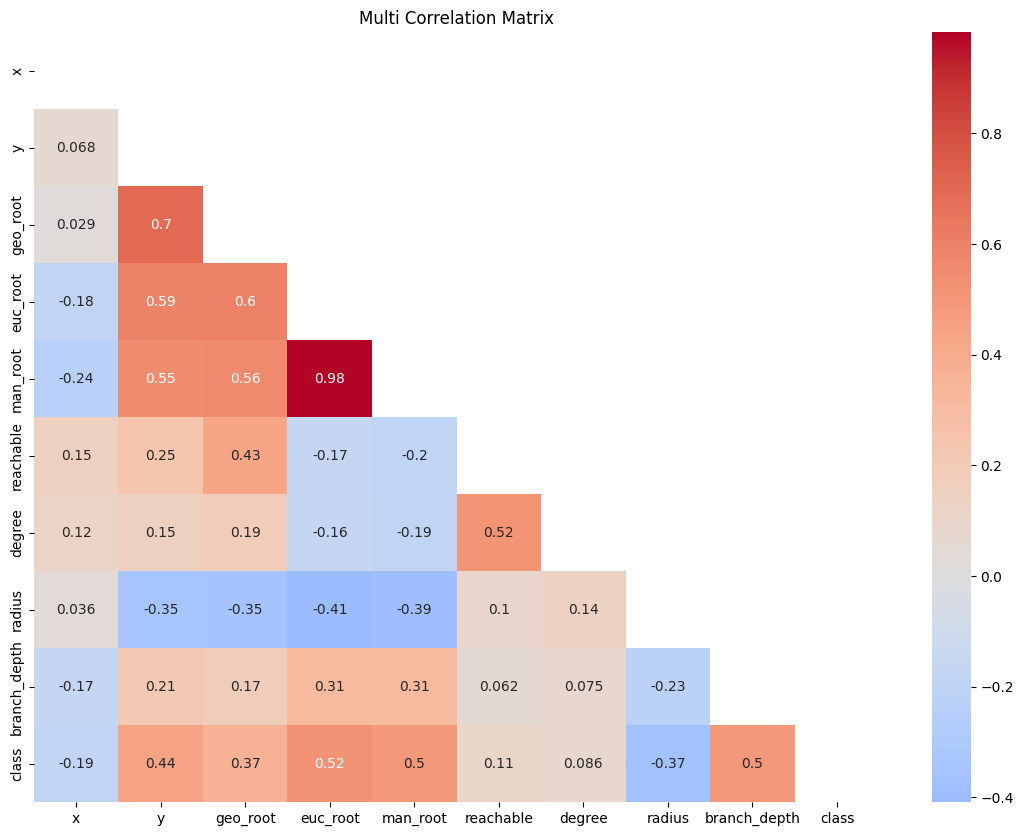

Counter({1: 62079, 3: 17011, 2: 13971, 4: 10875, 0: 459})


In [6]:
train_counts = draw_corl_matrix(train_images,feature_keys=args["selected_features"])

  0%|          | 0/55 [00:00<?, ?it/s]

-1.0 1.0


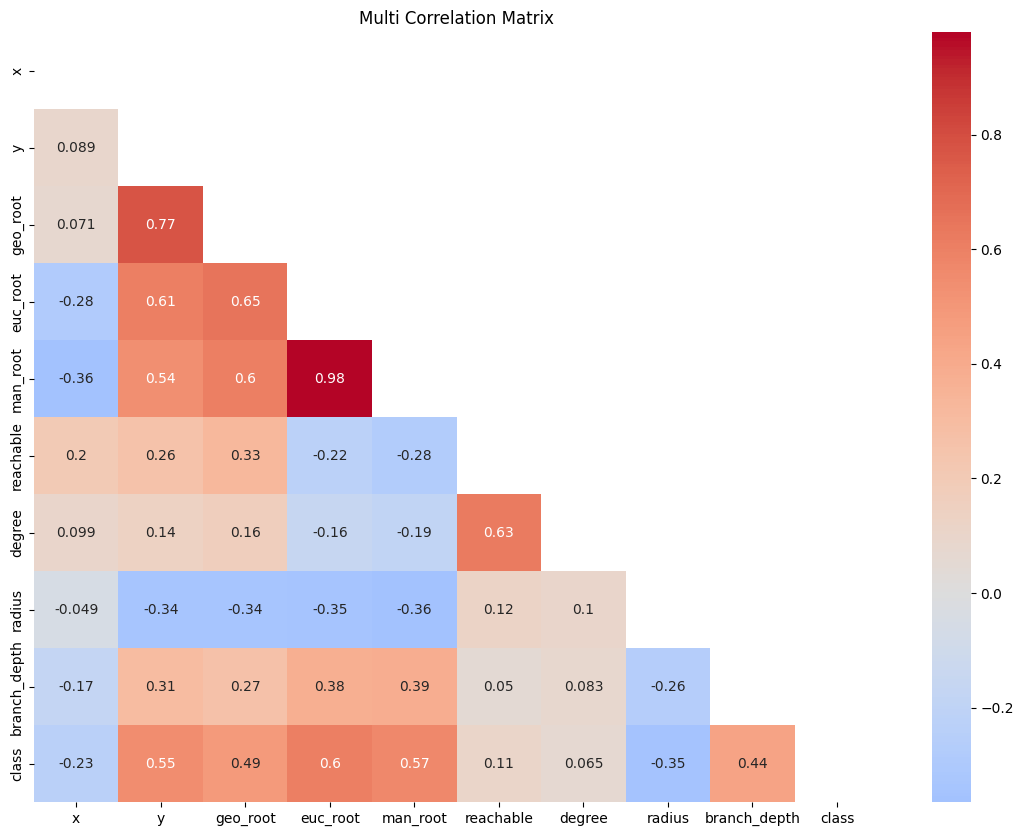

Counter({1: 7609, 3: 2827, 4: 1894, 2: 1811, 0: 55})


In [7]:
train_counts = draw_corl_matrix(valid_images,feature_keys=args["selected_features"])

In [8]:
def effective_number_weights(counts, beta=0.999,ignore_bg=True):
    """counts: per-class node counts for the REAL classes only (exclude bg)."""
    if(ignore_bg):
        counts = np.asarray(counts, dtype=np.float64)[1:]
        eff = (1.0 - np.power(beta, counts)) / (1.0 - beta)
        w = 1.0 / np.clip(eff, 1e-8, None)
        w = w / w.sum() * len(counts)
        w = w.tolist()
        return [0.0, *w]
    else:
        counts = np.asarray(counts, dtype=np.float64)
        eff = (1.0 - np.power(beta, counts)) / (1.0 - beta)
        w = 1.0 / np.clip(eff, 1e-8, None)
        w = w / w.sum() * len(counts)
        w = w.tolist()
        # return [0.0, *w]
        return w
        
    
counts = [0]*len(train_counts) 
for i in range(len(counts)):
    counts[i] = train_counts[i]
    
weights = effective_number_weights(counts, beta=0.999,ignore_bg = args["focal_coef"]["ignore_bg"])
args["focal_coef"]["alpha"] = weights
weights

[0.0,
 0.9022671358588977,
 1.0778859120672002,
 0.9584733418761688,
 1.0613736101977336]

In [9]:
train_transforms = A.Compose([
    
    ]
)
test_transforms = A.Compose([

    ]  
)

if(args["in_c"]==1):
    normalizer = normalize_xca
else:
    normalizer = A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
        max_pixel_value=255.0,
    )
train_preprocess = None


In [10]:
train_ds = GnnDataset(
    data = train_images , 
    part = "train",
    training_mode=args["training_mode"],
    transform = train_transforms,
    aug_args=aug_args
)
valid_ds = GnnDataset(
    data = valid_images , 
    part = "val",
    training_mode=args["training_mode"],
    transform = test_transforms,
)
test_ds = GnnDataset(
    data = test_images , 
    part = "test",
    training_mode=args["training_mode"],
    transform = test_transforms
)
if(args["training_mode"]=="side"):
    DataLoader = CNNDataLoader
else:
    DataLoader = GNNDataLoader
    


In [11]:
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Makes CUDA behavior more reproducible
    # torch.backends.cudnn.deterministic = True
    # torch.backends.cudnn.benchmark = False

In [12]:
train_loader = DataLoader(
    train_ds,
    batch_size = args["batch_size"] ,
    num_workers = args["num_workers"] ,
    persistent_workers=True if args["num_workers"]>0 else False,
    pin_memory=True,
    shuffle=True
)
valid_loader = DataLoader(
    valid_ds,
    batch_size = 1 ,
    pin_memory=True,
    shuffle=False,
)
test_loader = DataLoader(
    test_ds,
    batch_size = 1  ,
    pin_memory=True,
    shuffle=False,
)

In [13]:
# model,model_args,_ = load_model(
#     model_class = VesselGraphSAGE,
#     path=f"./outputs/2026-07-23_16-36-20 [full_gt_tests]/",
#     device="cuda",
#     return_args=True,
#     model_inputs={},
#     task_type="gnn"
# )

# res = permutation_importance(
#     model, valid_loader,
#     feature_names=model_args["selected_features"],
#     device="cuda",
#     include_bg=False,  
#     bg_label=0,
#     n_repeats=5,
#     group=[2, 3, 4],
# )
# print_report(res)


In [14]:
recorder = GnnHistoryRecorder(
    losses_keys = losses_keys,
    class_count = args["class_count"],
    training_mode = args["training_mode"]
)
print("training gnn mullti model")
# model = SimpleGCN(args).to(args["device"])
model = VesselGraphSAGE(args).to(args["device"])
optimizer = torch.optim.Adam(model.parameters(),**args["adam_conf"])


# optimizer = torch.optim.SGD(model.parameters(),**args["sgd_conf"])
loss_fn = GnnLoss(args)
lr_sch = None

best_model = trainer(
    args=args,
    recorder = recorder,
    model = model,
    optimizer = optimizer,
    loss_fn = loss_fn,
    train_loader = train_loader,
    valid_loader = valid_loader,
    lr_sch = lr_sch
)


training gnn mullti model
focal w is set to tensor([0.0000, 0.9023, 1.0779, 0.9585, 1.0614], device='cuda:0')
loss is set to focal


/home/parsa/Masters/Coronary Artry/Datasets/Arcade/codes/utils/losses.py:570: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  weight = torch.tensor(weight)


  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/46 [00:00<?, ?it/s]

--- Total Norm ---
tensor(1.4537, device='cuda:0')
--- Total Norm ---
tensor(2.5701, device='cuda:0')
--- Total Norm ---
tensor(1.4512, device='cuda:0')
--- Total Norm ---
tensor(1.3881, device='cuda:0')
--- Total Norm ---
tensor(1.5596, device='cuda:0')
train [0]:
losses :total loss:0.62981|
metrics: f1:0.23795|per:0.28235|rec:0.24230
acc:0.56676|auc:0.26313|m_auc:0.23867
mcc:0.12438
val [0]:
losses :total loss:0.35099|
metrics: f1:0.45110|per:0.55976|rec:0.42002
acc:0.68442|auc:0.50919|m_auc:0.29554
mcc:0.47427
New Best! : F1 = 0.45110343779003725


  0%|          | 0/46 [00:00<?, ?it/s]

... (793 outputs left out)

  0%|          | 0/46 [00:00<?, ?it/s]

--- Total Norm ---
tensor(0.8825, device='cuda:0')
--- Total Norm ---
tensor(1.0674, device='cuda:0')
train [398]:
losses :total loss:0.14650|
metrics: f1:0.61707|per:0.62450|rec:0.61067
acc:0.84554|auc:0.68662|m_auc:0.28771
mcc:0.73375
val [398]:
losses :total loss:0.32353|
metrics: f1:0.55095|per:0.55446|rec:0.57239
acc:0.75838|auc:0.57404|m_auc:0.33451
mcc:0.64059


  0%|          | 0/46 [00:00<?, ?it/s]

--- Total Norm ---
tensor(0.4540, device='cuda:0')
--- Total Norm ---
tensor(0.9925, device='cuda:0')
--- Total Norm ---
tensor(0.3623, device='cuda:0')
--- Total Norm ---
tensor(1.2242, device='cuda:0')
--- Total Norm ---
tensor(0.7704, device='cuda:0')
--- Total Norm ---
tensor(1.4513, device='cuda:0')
--- Total Norm ---
tensor(0.6170, device='cuda:0')
train [399]:
losses :total loss:0.12244|
metrics: f1:0.63592|per:0.63884|rec:0.63481
acc:0.86249|auc:0.70441|m_auc:0.28943
mcc:0.76470
val [399]:
losses :total loss:0.38971|
metrics: f1:0.52631|per:0.51372|rec:0.54860
acc:0.72387|auc:0.54158|m_auc:0.32573
mcc:0.59457
best result at epoch 64 with f1 0.5944201723207811


In [15]:
example_dataloaders = make_gnn_exmaple_loaders(
    args=args,
    train_images=train_images,
    valid_images=valid_images,
    transform = test_transforms,
    Example_DL = DataLoader
)

In [16]:
# calaculate_dataset_quality(
#     dataloaders=example_dataloaders,
#     paths=args["paths"],
#     class_count=args["class_count"],
#     use_binary_model = args["gnn_simple"]["use_binary_model"]
# )

In [17]:
# best_model,model_args,_ = load_model(
#     model_class = VesselGraphSAGE,
#     path=f"./outputs/2026-07-23_16-36-20 [full_gt_tests]/",
#     device="cuda",
#     return_args=True,
#     model_inputs={},
#     task_type="gnn"
# )
# from torch_geometric.explain import Explainer, GNNExplainer

# # Initialize the explainer
# explainer = Explainer(
#     model=best_model,
#     algorithm=GNNExplainer(epochs=200),
#     explanation_type='model',
#     node_mask_type='attributes', # Analyzes specific feature importance
#     edge_mask_type='object',     # Analyzes specific edge importance
#     model_config=dict(
#         mode='multiclass_classification',
#         task_level='node', 
#         return_type='raw', 
#     ),
# )
# for data,labels,name in valid_loader:
#     print(name)
#     if(name[0] == "14"):
#         print(1)
#         x = data.x.squeeze(0).to("cuda")
#         edge_index = data.edge_index.squeeze(0).to("cuda")
    
#         # Generate an explanation for a specific node (e.g., index 0)
#         explanation = explainer(x, edge_index, index=0)

#         # Save the visualizations
#         explanation.visualize_feature_importance(top_k=10, path="./feature_importance.png")
#         explanation.visualize_graph(path="./subgraph.png")

Save Model
Saving Memory
generate report
train evaluation Report
=+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+=
              precision    recall  f1-score   support

          bg       0.00      0.00      0.00       459
          16       0.99      0.97      0.98     62079
         16a       0.93      0.99      0.96     13971
         16b       0.96      0.84      0.90     17011
         16c       0.80      0.99      0.88     10875

    accuracy                           0.95    104395
   macro avg       0.74      0.76      0.74    104395
weighted avg       0.95      0.95      0.95    104395

val evaluation Report
=+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+=
              precision    recall  f1-score   support

          bg       0.00      0.00      0.00        55
          16       0.96      0.80      0.87      7609
         16a       0.59      0.75      0.66      1811
         16b       0.52  

  0%|          | 0/14 [00:00<?, ?it/s]

  0%|          | 0/459 [00:00<?, ?it/s]

dice train: tensor([1.0000, 0.9844, 0.9561, 0.8994, 0.8731]) tensor(0.9282)


,class,dice
0,bg,0.999998
1,16,0.984422
2,16a,0.956051
3,16b,0.899362
4,16c,0.873103
5,mean dice,0.928235


--------


... (4 outputs left out)

100%|██████████| 8/8 [00:00<00:00, 1849.03it/s]


processing ./utils/dataset.py
processing ./utils/helpers.py
processing ./scripts/gnn_logger.py
processing ./utils/recorder.py
processing ./utils/graph_extraction.py
processing ./models/gnn_model.py
processing ./utils/losses.py
processing ./scripts/gnn_trainer.py


100%|██████████| 1/1 [00:00<00:00,  3.05it/s]

processing ./temp_script.py


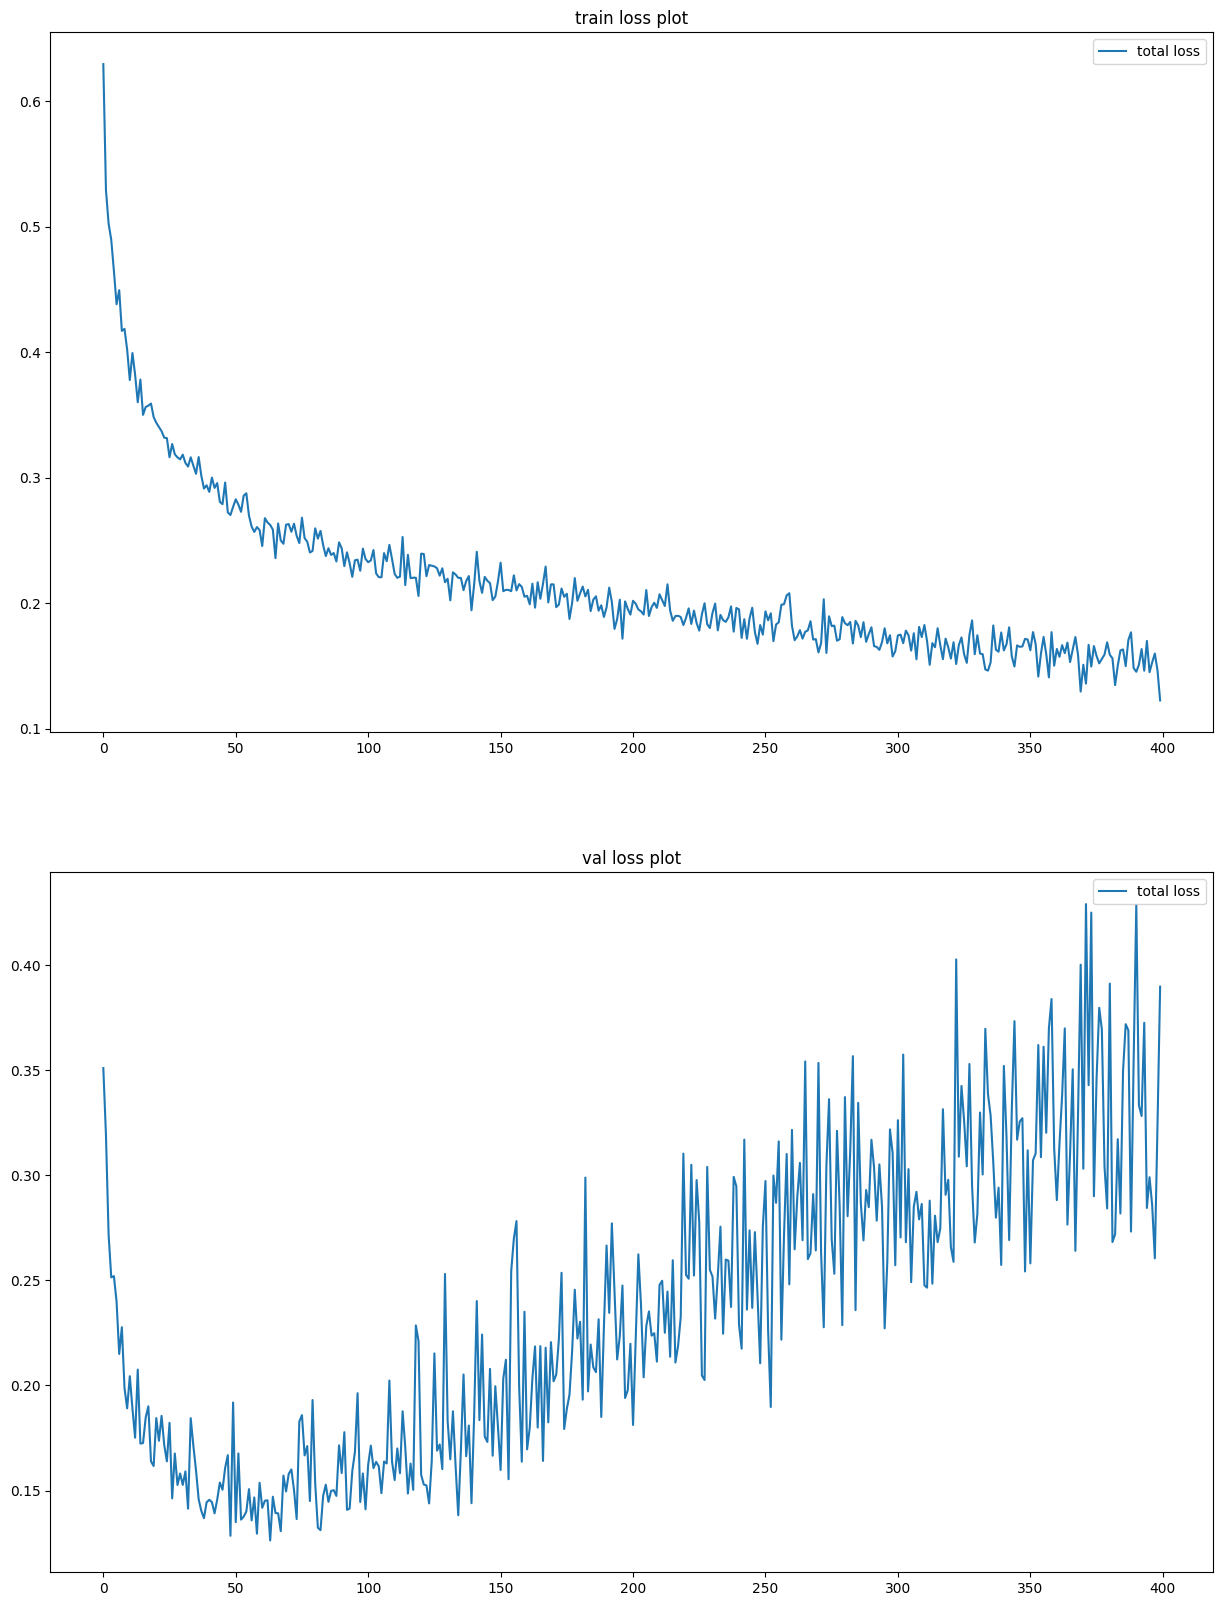

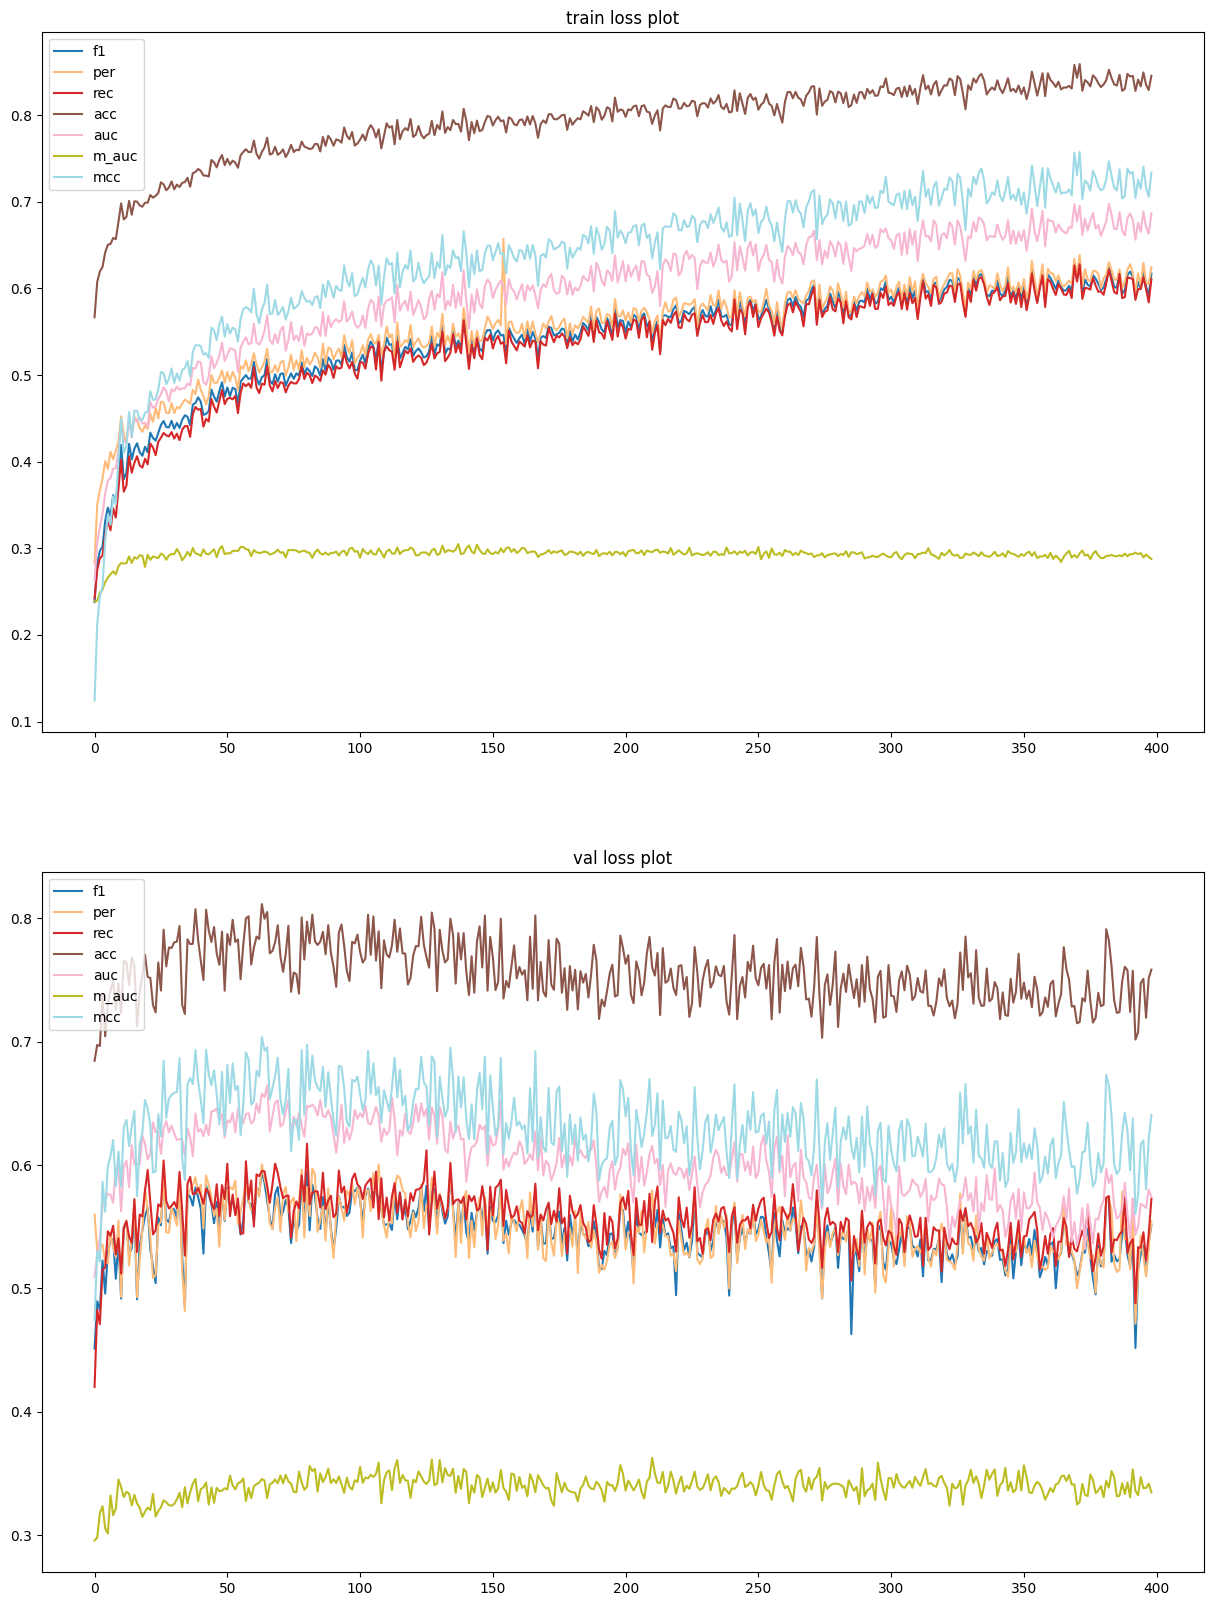

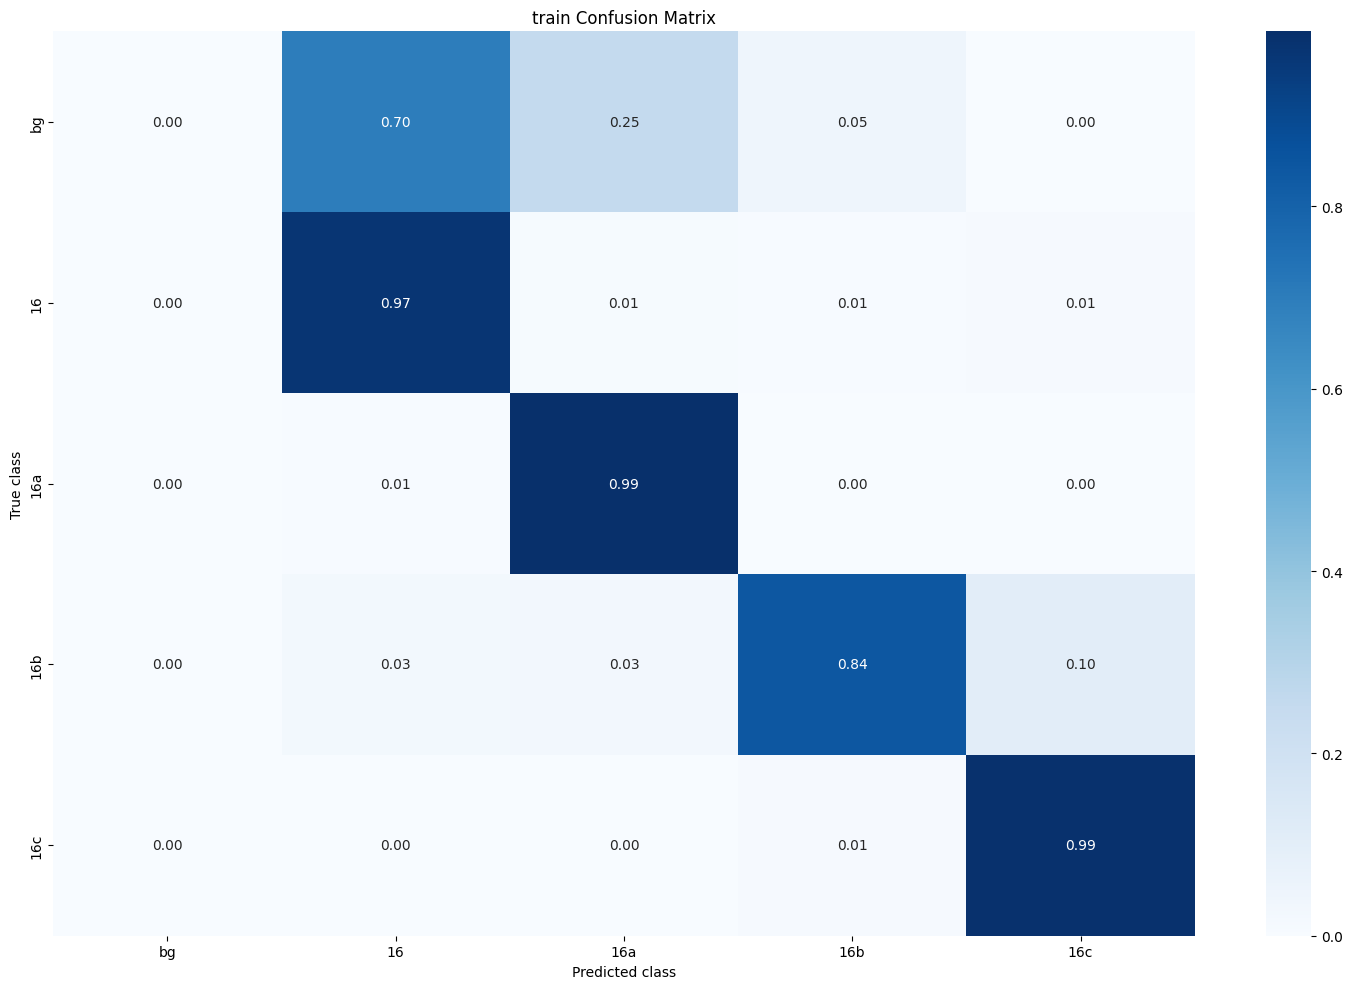

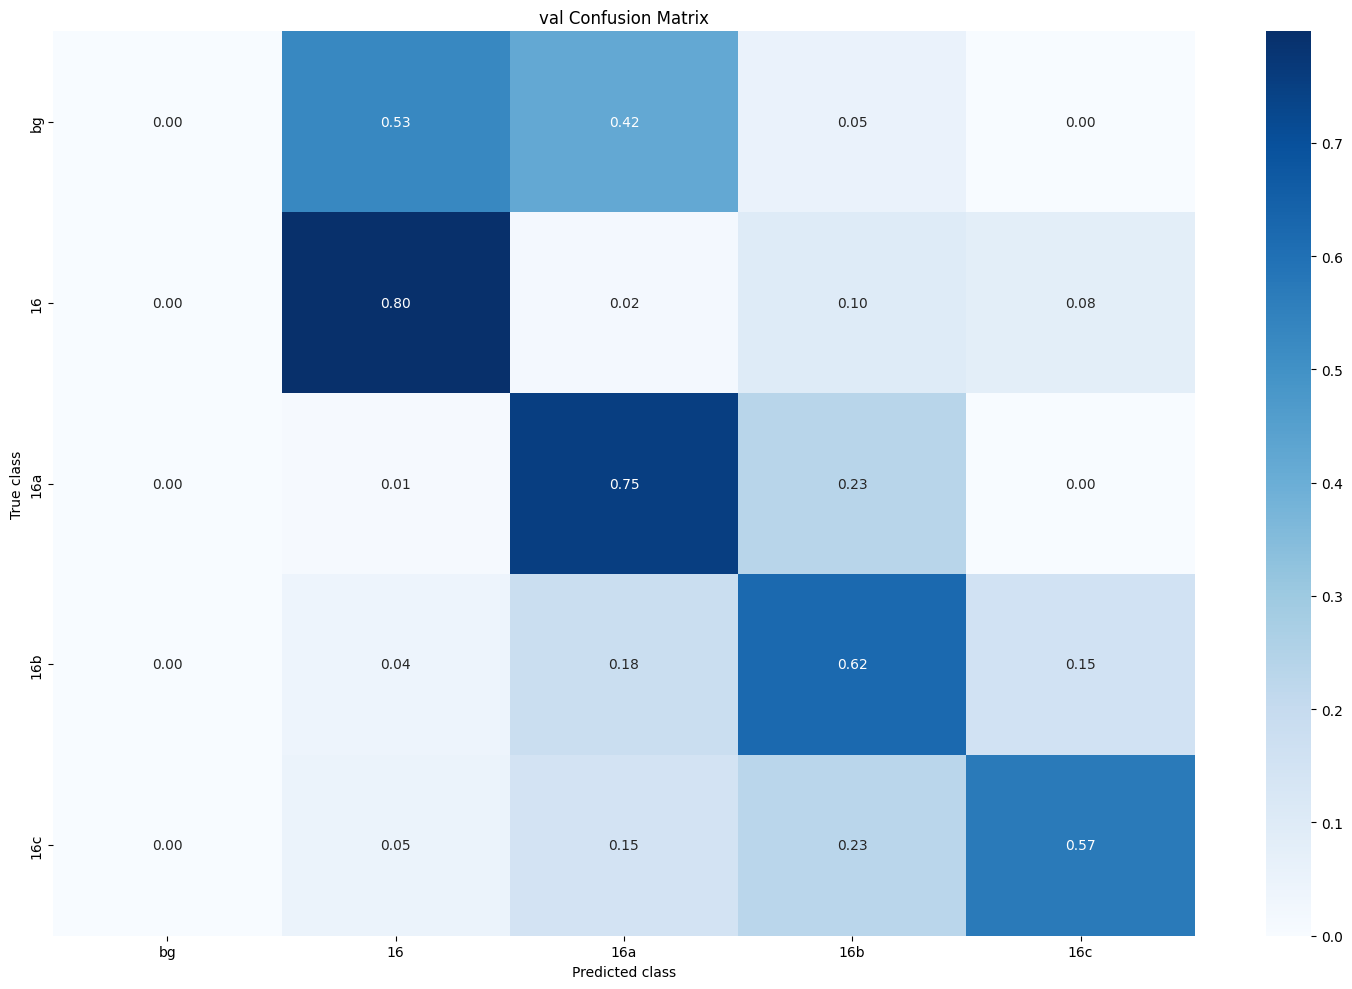

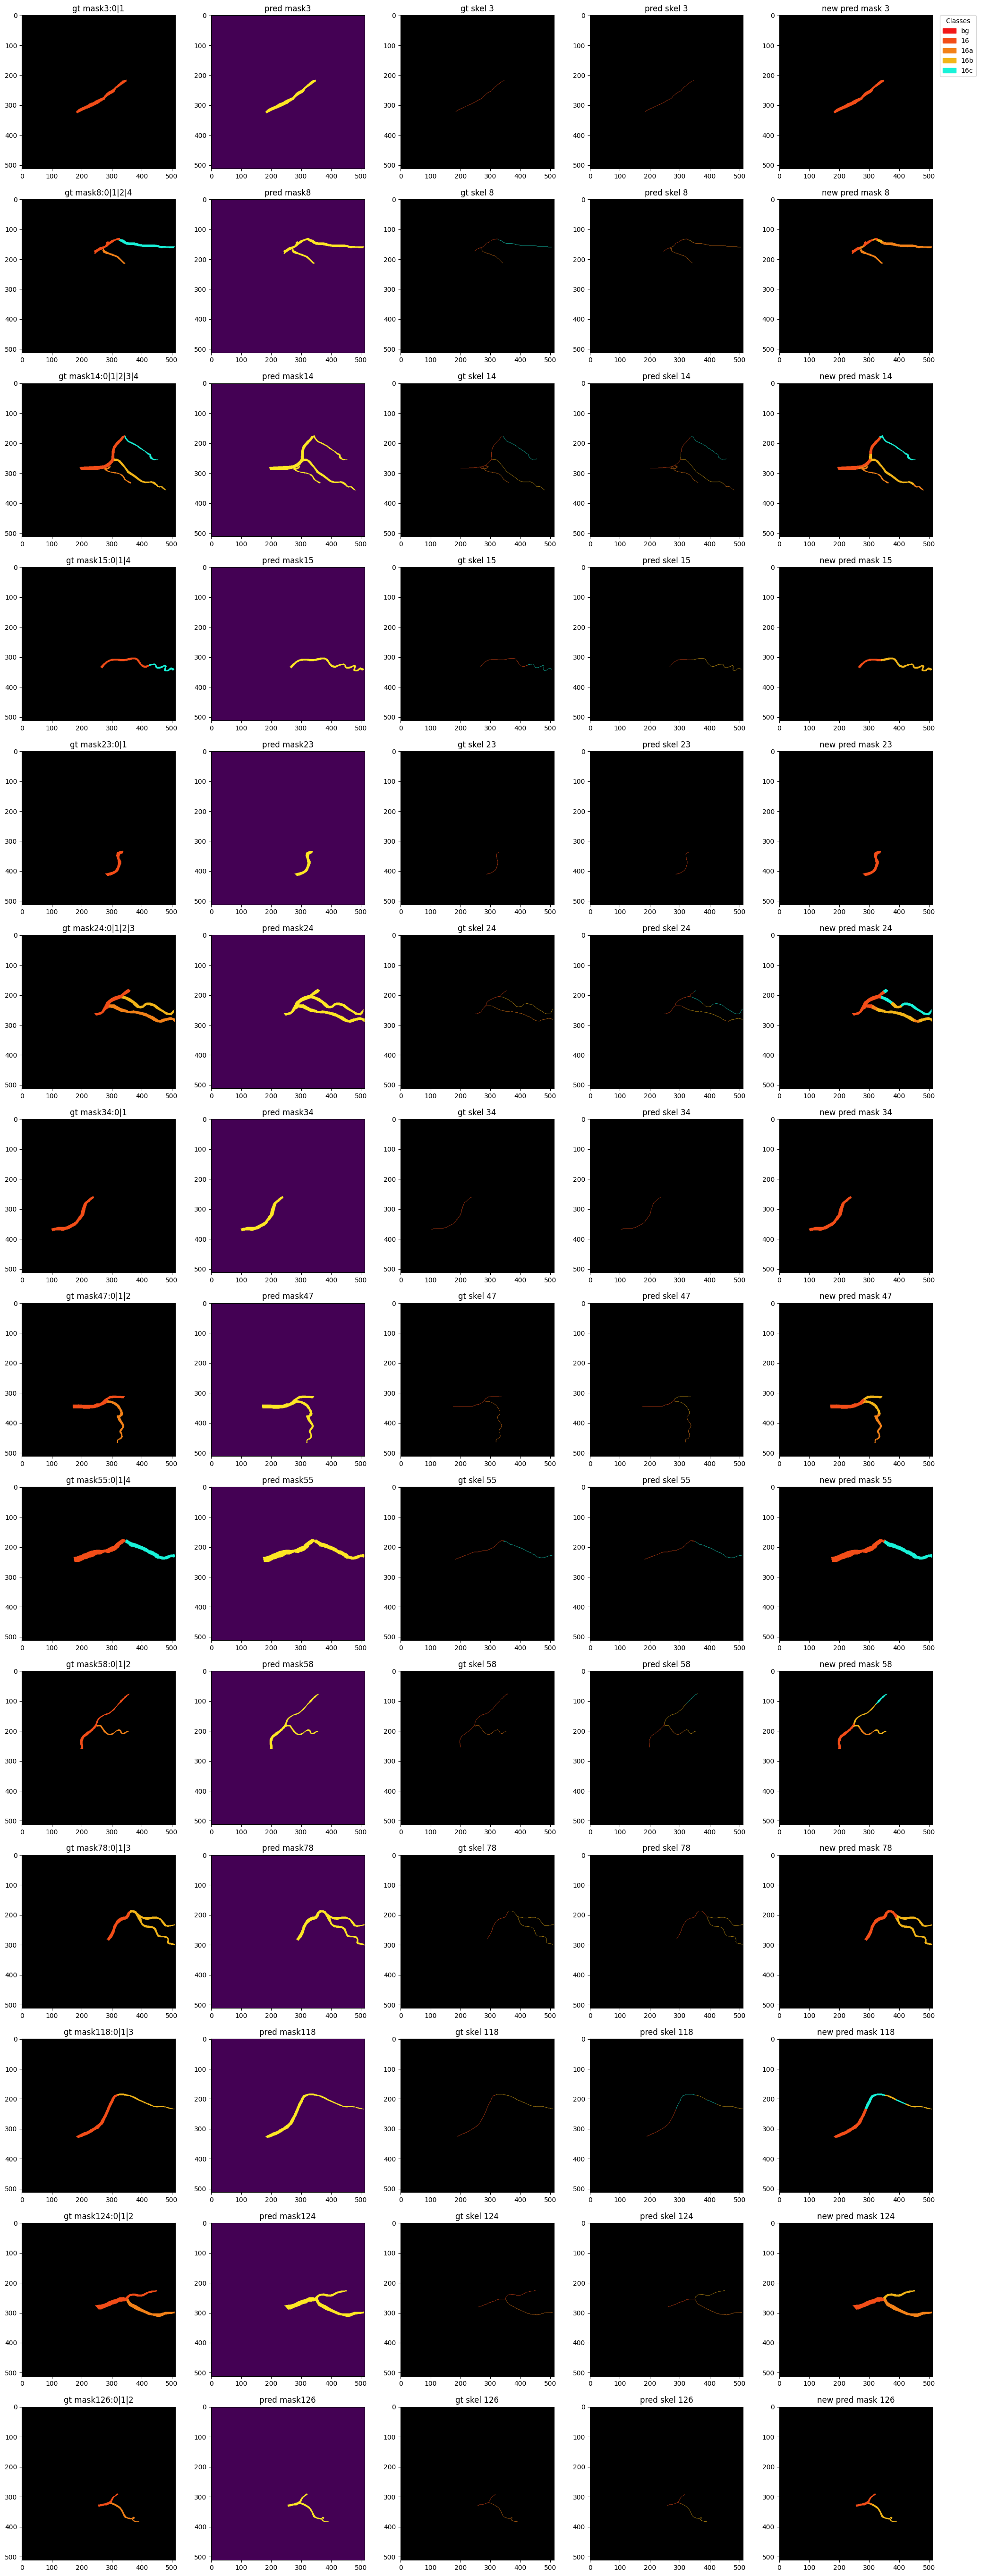

In [18]:
save_full_report(
    recorder = recorder,
    dataloaders= example_dataloaders,
    model = best_model,
    output_base_path=args["paths"]["output_base_path"],
    args=args,
    class_map=class_map,
    name=args["name"],
    training_mode = args["training_mode"],
    chosen_index = chosen_index,
    class_names = class_names
)
#0.611007159